# From a Rosetta loading hang to playable BO2 Zombies

A systems-debugging walkthrough of Windows debug-register semantics in Wine on Apple Silicon.

**Outcome:** the patched engine loaded a Zombies map and allowed movement/play, confirmed manually by the user. All 24 generic execution-breakpoint matrix cases passed. Isolated Wine exception tests reported 281 assertions and zero failures.

**Status:** working opt-in implementation, committed locally; upstream acceptance is a separate step. Ordinary application TF + 32-bit CALL still has a documented stack anomaly.

This notebook reads the committed measurement files and renders its figures without launching Wine, accessing a bottle or installing plotting libraries. Python 3 and Jupyter/IPython are sufficient. Saved outputs are included for browsing.

## 1. Separate state from behavior

The original game stalled while loading `code_pre_gfx_zm`. Wine reported that installing debug registers under Rosetta was unsupported. That was a hypothesis, not proof of the cause.

The investigation first asked whether a context round trip preserved DR0–DR3, DR6 and DR7. Patch 1 added coherent per-thread shadow state in `server/mach.c`. The generic baseline then established that readback could succeed while execution breakpoints delivered **zero exceptions**.

A Windows-visible execution breakpoint also needs an exception at the target PC, hit reporting in DR6, and correct continuation. That distinction motivated the second commit.

In [1]:
import json, re
from pathlib import Path
from IPython.display import SVG, display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "test-results/validation-2026-10-08.json").is_file())
validation = json.loads((root / "test-results/validation-2026-10-08.json").read_text())
baseline = json.loads((root / "test-results/baseline-2026-10-08.json").read_text())
rows = [r for r in validation["matrix"]
        if re.search(r"matrix(?:32|64)\.exe$", r["args"][1])]
assert len(rows) == 24
assert all(r["exit"] == 0 for r in rows)
print(f"Execution-breakpoint matrix: {len(rows)}/24 passed")
for record in validation["upstream_isolated_tests"]:
    summary = re.search(r"\d+ tests executed.*?\d+ skipped\.", record["output"])
    print(record["arch"], "exit", record["exit"], "—", summary.group(0))


Execution-breakpoint matrix: 24/24 passed
i386 exit 0 — 126 tests executed (0 marked as todo, 0 as flaky, 0 failures), 0 skipped.
x86_64 exit 0 — 155 tests executed (0 marked as todo, 0 as flaky, 0 failures), 0 skipped.


## 2. Preserve Windows breakpoint semantics

For slot $i$, the experiment matches the current program counter against DR$i$ when its local/global enable bits are nonzero and its RW/LEN encoding specifies execution:

$$h_i = \mathbf{1}[PC = DR_i]\;\mathbf{1}[enable_i \ne 0]\;\mathbf{1}[RW/LEN_i = 0]\;\mathbf{1}[\neg RF_{suppression}].$$

The reported hit mask is $H = \sum_{i=0}^{3}2^i h_i$. Two enabled slots at the same address must therefore report $H=3$, rather than selecting only one slot.

The opt-in implementation uses internal TF stepping, retains application TF separately, and dispatches through Wine's existing exception machinery. It hides its internal TF from context reads. RF suppression must survive the WOW64 host-to-guest transition so that unchanged continuation does not immediately refire.

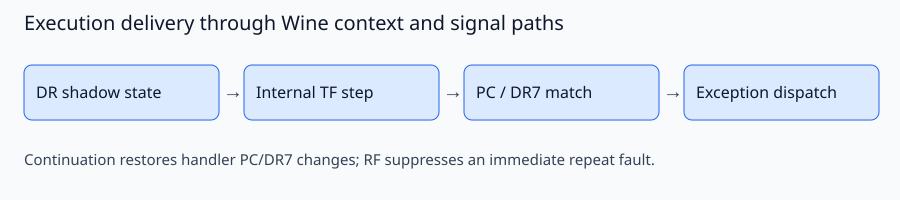

In [2]:
svg = """<svg xmlns="http://www.w3.org/2000/svg" width="900" height="200" viewBox="0 0 900 200">
<rect width="900" height="200" fill="#f8fafc"/>
<text x="24" y="30" font-family="sans-serif" font-size="20" fill="#0f172a">Execution delivery through Wine context and signal paths</text>
"""
labels = ["DR shadow state", "Internal TF step", "PC / DR7 match", "Exception dispatch"]
for i, label in enumerate(labels):
    x = 24 + i * 220
    svg += f'<rect x="{x}" y="65" width="195" height="55" rx="8" fill="#dbeafe" stroke="#2563eb"/>'
    svg += f'<text x="{x+12}" y="98" font-family="sans-serif" font-size="16" fill="#0f172a">{label}</text>'
    if i < 3:
        svg += f'<text x="{x+199}" y="98" font-size="20" fill="#334155">→</text>'
svg += '<text x="24" y="165" font-family="sans-serif" font-size="15" fill="#334155">Continuation restores handler PC/DR7 changes; RF suppresses an immediate repeat fault.</text></svg>'
display(SVG(svg))


## 3. Inspect every matrix row

Green cells below mean the probe met its expected assertions and exited successfully. These expectations were checked against the observed Wine behavior; a Windows reference run was not performed. Baseline probes reported zero execution hits, so they could not validate handler continuation or DR6 delivery.


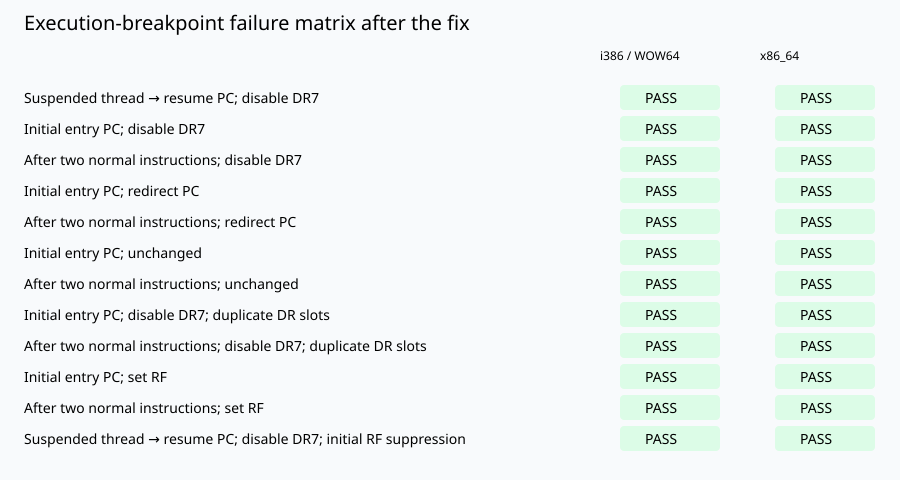

In [3]:
from html import escape
by_arch = {}
for r in rows:
    bits = re.search(r"matrix(32|64)\.exe$", r["args"][1]).group(1)
    by_arch.setdefault(bits, []).append(r)
assert all(len(by_arch[b]) == 12 for b in ["32", "64"])
locations = {"0": "After two normal instructions", "1": "Initial entry PC", "2": "Suspended thread → resume PC"}
actions = {"0": "disable DR7", "1": "redirect PC", "2": "unchanged", "3": "set RF"}
svg = '<svg xmlns="http://www.w3.org/2000/svg" width="900" height="480" viewBox="0 0 900 480"><rect width="900" height="480" fill="#f8fafc"/>'
svg += '<text x="24" y="30" font-family="sans-serif" font-size="20">Execution-breakpoint failure matrix after the fix</text>'
svg += '<text x="600" y="60" font-family="sans-serif">i386 / WOW64</text><text x="760" y="60" font-family="sans-serif">x86_64</text>'
for i, record in enumerate(by_arch["32"]):
    loc, action, duplicate, rf = record["args"][2:]
    label = locations[loc] + "; " + actions[action]
    if duplicate == "1": label += "; duplicate DR slots"
    if rf == "1": label += "; initial RF suppression"
    y = 85 + i * 31
    svg += f'<text x="24" y="{y+18}" font-family="sans-serif" font-size="14">{escape(label)}</text>'
    for bits, x in [("32", 620), ("64", 775)]:
        assert by_arch[bits][i]["args"][2:] == record["args"][2:]
        passed = by_arch[bits][i]["exit"] == 0
        color = "#dcfce7" if passed else "#fee2e2"
        svg += f'<rect x="{x}" y="{y}" width="100" height="25" rx="4" fill="{color}"/>'
        svg += f'<text x="{x+25}" y="{y+18}" font-family="sans-serif" font-size="14">{"PASS" if passed else "FAIL"}</text>'
svg += '</svg>'
display(SVG(svg))


## 4. Diagnose the separate CALL stack anomaly

For an ordinary 32-bit near CALL, the expected stack displacement is

$$\Delta_{CALL}=ESP_{before}-ESP_{callee}=4,\qquad D=ESP_{after\ RET}-ESP_{before}=0.$$

The recorded baseline example was:

| Mode | Before CALL | At callee | After RET | CALL decrement | Net drift |
|---|---|---|---|---|---|
| TF off | `0036fbcc` | `0036fbc8` | `0036fbcc` | 4 bytes | 0 |
| TF on | `0036fbcc` | `0036fbc4` | `0036fbc8` | 8 bytes | −4 bytes |

A raw Darwin trap-context observation matched the Windows-visible PC/SP before Wine's normal handler. The evidence supports a change in guest stack state, rather than only a four-byte reporting error. It does not establish the internals of Rosetta's translator.

A bare `ESP += 4` would discard the return-address position. The separately gated workaround validates an unprefixed E8 instruction, its destination, an eight-byte decrement and the return-address words; it moves the return DWORD to `[ESP+4]` before adjusting ESP. It applies only during internal breakpoint stepping.

**Remaining failure:** ordinary application TF + direct CALL is still affected. The successful internal-stepping probe must not be interpreted as a general fix for all application stepping.

In [4]:
call_rows = [r for r in validation["matrix"] if "internal-call" in r["args"][1]]
assert len(call_rows) == 2
for record in call_rows:
    assert record["exit"] == 0
    print(record["output"].strip())


bits=64 before=000000000031F990 callee=000000000031F988 after=000000000031F990 actual_delta=8 expected=8
bits=32 before=0032FBF4 callee=0032FBF0 after=0032FBF4 actual_delta=4 expected=4


## 5. What the integration result establishes

The user confirmed a Zombies map loaded and allowed movement/play with the patched WineCX runtime. That establishes progress beyond the original loading hang for the tested configuration. It does not prove long-session stability, controller operation or correctness for every Windows program.

The installed Whisky runtime and original bottle were left untouched. No game-specific address or guest executable patch was added to Wine. Standalone probes and regression tests make the mechanism reviewable independently of the game.

## 6. Contribution map

| Artifact | Role |
|---|---|
| Upstream commit `b81e0922706` | Rosetta debug-register shadow state |
| Next commit `6901e703d31` | Delivery, regression tests and independently gated CALL workaround |
| `patches/` | Reproducible upstream and WineCX exports |
| `probes/` | Generic context, delivery and stack reproductions |
| `test-results/` | Raw baseline and validation measurements |
| `bo2/` | Build and launch scripts; no runtime or game assets |

The contribution is committed locally. Upstream submission/acceptance, performance evaluation and broader signal-safety review remain separate work. This repository documents a working compatibility result without claiming an upstream merge.
